In [21]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import duecker_ET_model, simulate_dipole, jones_2009_model

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology
import decimal

# import pandas as pd
from scipy import signal
import sys
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_cells_dev/figures'

In [18]:

def stim_dpl(net, stim_cell='L5_pyramidal', stim_section='soma', stim_length=20, ampl=2.5):

    window_len, scaling_factor = 10, 1

    net.clear_connectivity()

    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2400,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    t0 = 20

    net.add_tonic_bias(cell_type=stim_cell,section=stim_section,bias_name='pulse',amplitude=ampl,t0=t0,tstop=t0+stim_length)

    dpl = simulate_dipole(net, tstop=80, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='none')
    smooth_dpl = dpl[0].copy()
    smooth_dpl.smooth(window_len).scale(scaling_factor)

    return net, dpl, smooth_dpl

def stim_hyperpol(net, stim_cell='L5_pyramidal'):

    window_len, scaling_factor = 10, 1

    net.clear_connectivity()

    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2400,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    ampl = -4
    t0 = 20

    for i in range(1):
        net.add_tonic_bias(cell_type=stim_cell,section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+150)

    dpl = simulate_dipole(net, tstop=200, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='none')
    smooth_dpl = dpl[0].copy()
    smooth_dpl.smooth(window_len).scale(scaling_factor)

    return net, dpl, smooth_dpl

def plot_dpl(net, dpl, smooth_dpl, axs, gid, cell_type, stim_length=20):

    cells = ['L5_pyramidal', 'L2_pyramidal']
    cols = np.array(([67, 104, 158], [164,30,79], [117,112,179], [231,41,138], [102,166,30]))/255
    c = cells.index(cell_type)


    timevec = net.cell_response.times

    v = net.cell_response.vsec[0][gid]['soma']
    v_apcl = net.cell_response.vsec[0][gid]['apical_tuft']

    if cell_type == 'L5_pyramidal':
        alpha = 1
        color_soma = 'k'
    else:
        alpha = 0.5
        color_soma = cols[c]

    axs[0].plot(timevec, v, color=color_soma, linewidth=1.5, alpha=alpha, label='soma')
    axs[0].plot(timevec, v_apcl, color=cols[c], linewidth=1.5, label='apical tuft')
    axs[0].legend(loc='lower right', fontsize=8)
    axs[0].set_ylabel('membrane potential mV')
    axs[0].set_ylim([-90, 60])
    axs[0].set_yticks([-70,0, 50])
    axs[0].spines['bottom'].set_bounds(0, 25)
    axs[0].spines['left'].set_bounds(0, 50)
    axs[0].spines['top'].set_visible(False)
    axs[0].spines['right'].set_visible(False)
    clamp = np.zeros_like(v)
    t0 = np.argmin(np.abs(timevec - 20))
    t1 = np.argmin(np.abs(timevec - (20+stim_length)))
    clamp[t0:t1] = 2.5
    axs[0].plot(timevec, clamp-85, color='r', linewidth=1., label='clamp')
    
    # convert dipole to nAm/mm2
    net_dict = net.cell_types[cell_type]['cell_object'].to_dict()
    basal_plane = np.abs(net_dict['sections']['basal_2']['end_pts'][1][0] - net_dict['sections']['basal_3']['end_pts'][1][0]) * net_dict['sections']['soma']['diam']

    surface_mm2 = basal_plane*1e-6

    


    axs[1].plot(timevec, dpl[0].data[cell_type[:2]]/surface_mm2, label='unsmoothed', color='k', linewidth=2, alpha=0.5)
    axs[1].plot(timevec, smooth_dpl.data[cell_type[:2]]/surface_mm2, label='smoothed', color='k', linewidth=2)
    axs[1].legend(loc='lower right', fontsize=8)
    axs[1].set_title('')
    axs[1].set_ylabel('dipole moment (nAm/mm2)')
    axs[1].set_ylim([-0.3, 0.3])
    axs[1].spines['top'].set_visible(False)
    axs[1].spines['right'].set_visible(False)
    axs[1].spines['bottom'].set_bounds(0, 25)
    axs[1].spines['left'].set_bounds(0, 0.2)

    for a in axs:
        a.set_xticks([])
        a.set_yticks([])

    return axs


def plot_atten(net, dpl, smooth_dpl, axs, gid, row_idx, cell_type):

    cells = ['L5_pyramidal', 'L2_pyramidal']
    cols = np.array(([67, 104, 158], [164,30,79], [117,112,179], [231,41,138], [102,166,30]))/255
    c = cells.index(cell_type)

    timevec = net.cell_response.times

    v = net.cell_response.vsec[0][gid]['soma']
    dist = []
    attenuation = []
    axs[0].plot(timevec, v, color="k", linewidth=1.5, alpha=0.5, label='soma')

    if cell_type == 'L5_pyramidal':
        sections = ['apical_trunk', 'apical_1','apical_2','apical_tuft']
    elif cell_type == 'L2_pyramidal':
        sections = ['apical_trunk', 'apical_1','apical_tuft']
    for i,sec in enumerate(sections):
        v_apcl = net.cell_response.vsec[0][gid][sec]
        sect_start = net.cell_types[cell_type].sections[sec].end_pts[0][-1]
        sect_end = net.cell_types[cell_type].sections[sec].end_pts[1][-1]
        dist.append(sect_start + (sect_end - sect_start)/2)
        atten = (np.max(v_apcl) - np.min(v_apcl))/ (np.max(v) - np.min(v))
        attenuation.append(atten*100)
        axs[0].plot(timevec, v_apcl, color=cols[c], alpha=0.1*(i+1),linewidth=1.5, label=sec)
    axs[0].legend(loc='bottom right', fontsize=8)
    axs[0].set_ylabel('membrane potential mV')
    # axs[row_idx,0].set_ylim([-90, 60])
    # axs[row_idx,0].set_yticks([-70,0, 50])
    axs[0].spines['top'].set_visible(False)
    axs[0].spines['right'].set_visible(False)

    axs[1].plot(np.array(dist), np.array(attenuation), marker='o', color=cols[c], label=cell_type)
    axs[1].set_ylabel('attenuation (%)')
    axs[1].set_ylim([0, 100])

    
    return axs

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1:

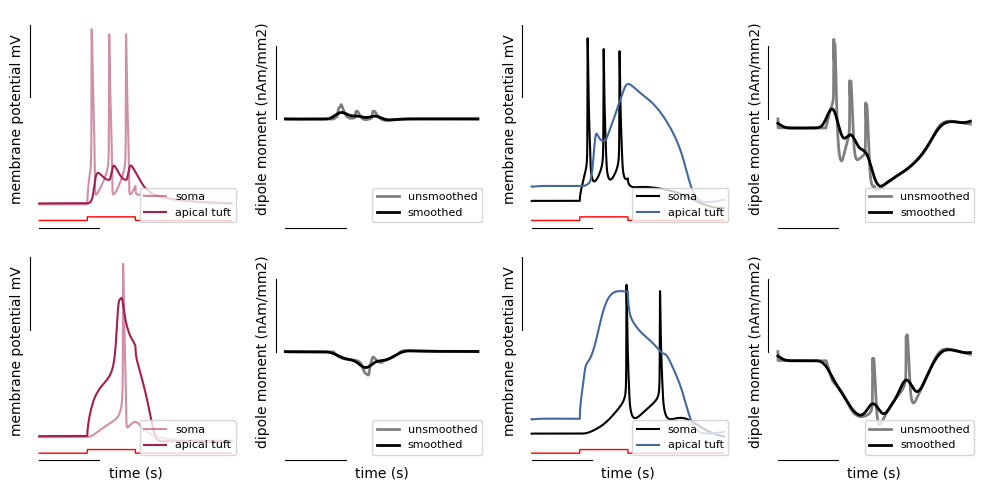

In [27]:
fig, axs = plt.subplots(2,4,figsize=(10,5), sharex=True)

gid = 1
net, dpl, smooth_dpl = stim_dpl(duecker_ET_model(mesh_shape=(1,1)), stim_cell='L2_pyramidal', ampl=2)

plot_dpl(net, dpl, smooth_dpl, axs[0,:2], gid, cell_type='L2_pyramidal')

net, dpl, smooth_dpl = stim_dpl(duecker_ET_model(mesh_shape=(1,1)), stim_cell='L2_pyramidal', stim_section='apical_tuft', ampl=0.6)

plot_dpl(net, dpl, smooth_dpl, axs[1,:2], gid, cell_type='L2_pyramidal')

gid = 3

net, dpl, smooth_dpl = stim_dpl(duecker_ET_model(mesh_shape=(1,1)), stim_cell='L5_pyramidal', ampl=3)

plot_dpl(net, dpl, smooth_dpl, axs[0,2:], gid, cell_type='L5_pyramidal')

net, dpl, smooth_dpl = stim_dpl(duecker_ET_model(mesh_shape=(1,1)), stim_cell='L5_pyramidal', stim_section='apical_tuft', ampl=1)
plot_dpl(net, dpl, smooth_dpl, axs[1,2:], gid, cell_type='L5_pyramidal')


for ax in axs[1,:]:
        ax.set_xlabel('time (s)')

fig.tight_layout()

fig.savefig(os.path.join(pathfig, 'dipolar_currents_pyramidal_cells.pdf'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(pathfig, 'dipolar_currents_pyramidal_cells.png'), dpi=300, bbox_inches='tight')

In [26]:
net.cell_types['L5_pyramidal']['cell_object'].to_dict()

{'name': 'L5Pyr',
 'pos': (0, 0, 0),
 'sections': {'apical_trunk': {'L': 102.0,
   'diam': 10.2,
   'cm': 1,
   'Ra': 100,
   'end_pts': [[np.float64(0.0), np.float64(0.0), np.float64(39.0)],
    [np.float64(0.0), np.float64(0.0), np.float64(141.0)]],
   'nseg': 3,
   'v': -71.50652549683365,
   'mechs': {'NaTa_t': {'gbar_NaTa_t': 0.01065},
    'SKv3_1': {'gbar_SKv3_1': 0.000261},
    'Ca_HVA': {'gbar_Ca_HVA': [[np.float64(0.16666666666666666),
       np.float64(0.5),
       np.float64(0.8333333333333333)],
      [np.float64(1.9608266666666667e-05),
       np.float64(2.3074000000000003e-05),
       np.float64(2.6539733333333333e-05)]]},
    'Ca_LVAst': {'gbar_Ca_LVAst': [[np.float64(0.16666666666666666),
       np.float64(0.5),
       np.float64(0.8333333333333333)],
      [np.float64(4.8931666666666664e-05),
       np.float64(5.025625e-05),
       np.float64(5.158083333333333e-05)]]},
    'SK_E2': {'gbar_SK_E2': 0.0036},
    'pas': {'g_pas': 3.926666666666667e-05, 'e_pas': -85},
    '

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...


AttributeError: 'numpy.ndarray' object has no attribute 'plot'

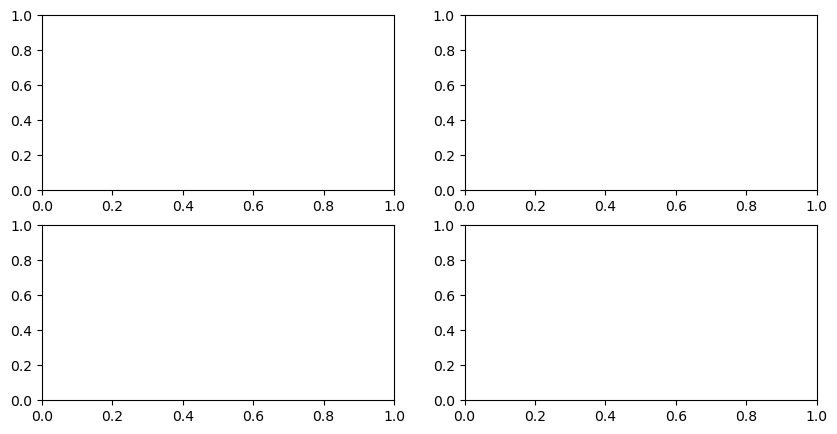

In [ ]:
# fig, axs = plt.subplots(2,2,figsize=(10,5))

# gid = 1
# net, dpl, smooth_dpl = stim_dpl(jones_2009_model(mesh_shape=(1,1)), stim_cell='L2_pyramidal')

# plot_atten(net, dpl, smooth_dpl, axs, gid, 0, cell_type='L2_pyramidal')

# gid = 3

# net, dpl, smooth_dpl = stim_dpl(jones_2009_model(mesh_shape=(1,1)), stim_cell='L5_pyramidal')

# plot_atten(net, dpl, smooth_dpl, axs, gid, 1, cell_type='L5_pyramidal')

# for ax in axs[1,:]:
#         ax.set_xlabel('time (s)')

# fig.tight_layout()

# fig.savefig(os.path.join(pathfig, 'jones_2009_dipolar_currents_pyramidal_cells.pdf'), dpi=300, bbox_inches='tight')
# fig.savefig(os.path.join(pathfig, 'jones_2009dipolar_currents_pyramidal_cells.png'), dpi=300, bbox_inches='tight')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 

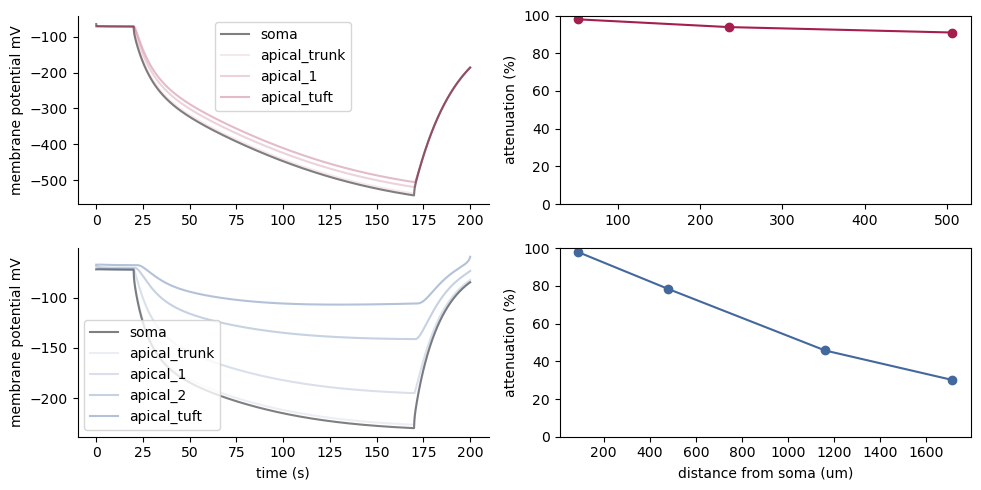

In [ ]:
# fig, axs = plt.subplots(2,2,figsize=(10,5))

# gid = 1
# net, dpl, smooth_dpl = stim_hyperpol(jones_2009_model(mesh_shape=(1,1)), stim_cell='L2_pyramidal')

# plot_atten(net, dpl, smooth_dpl, axs, gid, 0, cell_type='L2_pyramidal')

# gid = 3

# net, dpl, smooth_dpl = stim_hyperpol(jones_2009_model(mesh_shape=(1,1)), stim_cell='L5_pyramidal')

# plot_atten(net, dpl, smooth_dpl, axs, gid, 1, cell_type='L5_pyramidal')

# axs[1,0].set_xlabel('time (s)')
# axs[1,1].set_xlabel('distance from soma (um)')

# fig.tight_layout()

# fig.savefig(os.path.join(pathfig, 'jones_2009_hyperpol.pdf'), dpi=300, bbox_inches='tight')
# fig.savefig(os.path.join(pathfig, 'jones_2009_hyperpol.png'), dpi=300, bbox_inches='tight')